## M0 Concepts
This notebook covers the fundamental concepts and terms need to understand the topic problems, concepts and solutions.



## 0. Setup
This notebook are purely my personal notes. Because I keep forgetting the concepts and terms, I write them down here for future reference.

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc


## 1. Intersection over Union (IoU)

### 📘 Definition
**Intersection over Union (IoU)** is a common metric for evaluating the accuracy of an object detector.
It measures how much the **predicted bounding box** overlaps with the **ground truth box**.

Formally:

> **IoU = (Area of Overlap) / (Area of Union)**

A higher IoU indicates better alignment between prediction and ground truth.

<table>
<tr>
<td><img src="https://b2633864.smushcdn.com/2633864/wp-content/uploads/2016/09/iou_stop_sign.jpg?lossy=2&strip=1&webp=1" width="400" alt="IoU example"></td>
<td><img src="https://b2633864.smushcdn.com/2633864/wp-content/uploads/2016/09/iou_equation.png?lossy=2&strip=1&webp=1" alt="IoU equation"></td>
</tr>
</table>



## 2. Precision, Recall, PR Curve
### 📘 Definitions
- **Precision**: The ratio of true positive predictions to the total predicted positives.
- **Recall**: Shows how many of the actual objects the model successfully found — in other words, how many real targets it didn’t miss.
- **Trade-off**: Increasing precision often decreases recall, and vice versa. Hence, the higher the confidence threshold, the higher the precision but the lower the recall.
- **PR Curve**: A graph that shows the trade-off between precision and recall at different confidence thresholds. We can calculate the area under this curve to get the *Average Precision (AP)* score.

### 📊 Calculations
- **Precision** = TP / (TP + FP)
- **Recall** = TP / (TP + FN)
- **Average Precision (AP)**: The area under the PR curve.

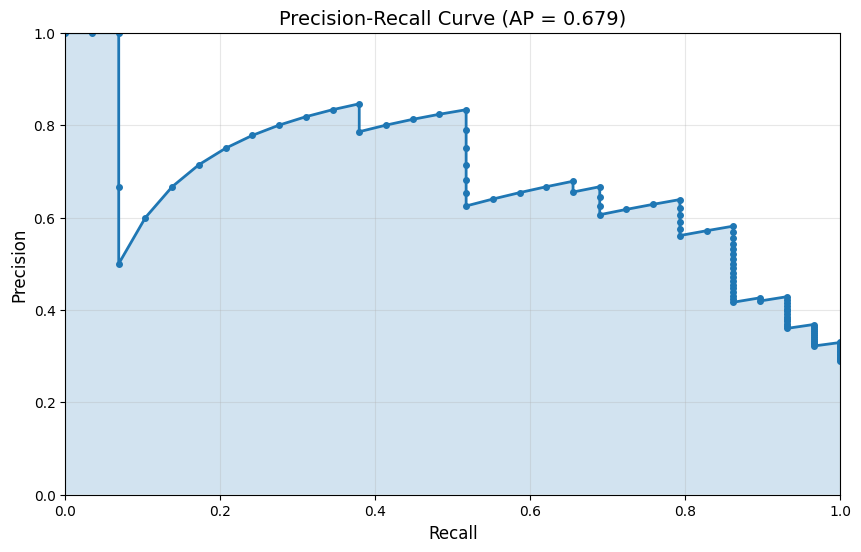

Average Precision (AP): 0.679

Sample metrics at different confidence thresholds:
Threshold    Precision    Recall      
------------------------------------
0.075        0.322        1.000       
0.271        0.386        0.931       
0.472        0.500        0.862       
0.707        0.667        0.690       
0.895        0.800        0.276       


In [3]:
# Simulate predictions and ground truth for a toy problem
np.random.seed(42)

# Generate 100 predictions with confidence scores and binary labels
# 1 = correct detection (TP), 0 = false detection (FP)
n_samples = 100
confidence_scores = np.random.rand(n_samples)
# Simulate that higher confidence tends to be more accurate
y_true = (confidence_scores + np.random.randn(n_samples) * 0.3 > 0.7).astype(int)

# Calculate precision and recall at different thresholds
precision, recall, thresholds = precision_recall_curve(y_true, confidence_scores)

# Calculate Average Precision (area under PR curve)
ap_score = auc(recall, precision)

# Plot the PR Curve
plt.figure(figsize=(10, 6))
plt.plot(recall, precision, marker='o', linewidth=2, markersize=4)
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title(f'Precision-Recall Curve (AP = {ap_score:.3f})', fontsize=14)
plt.grid(True, alpha=0.3)
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.fill_between(recall, precision, alpha=0.2)
plt.show()

# Display metrics at different confidence thresholds
print(f"Average Precision (AP): {ap_score:.3f}\n")
print("Sample metrics at different confidence thresholds:")
print(f"{'Threshold':<12} {'Precision':<12} {'Recall':<12}")
print("-" * 36)
for i in [10, 30, 50, 70, 90]:
    if i < len(thresholds):
        print(f"{thresholds[i]:<12.3f} {precision[i]:<12.3f} {recall[i]:<12.3f}")

## 3. AP and mAP
### 📘 Definitions
- **Average Precision (AP)**: The area under the Precision-Recall curve for a single class. It summarizes the model's precision and recall performance across all confidence thresholds.
- **Mean Average Precision (mAP)**: The mean of the AP scores across all classes. It provides an overall measure of the model's performance in multi-class object detection tasks.
- **Conventions**:
    - VOC AP@0.5: IoU threshold of 0.5. Historically used in PASCAL VOC challenges.
    - COCO mAP@[0.5:0.95]: Average mAP over multiple IoU thresholds from 0.5 to 0.95 in increments of 0.05. This is a more stringent metric used in COCO challenges.
        - Note: mAP@[.5:.95] means: Compute AP (Average Precision) at IoU = 0.50, 0.55, 0.60, …, up to 0.95 (10 values total). Then take the mean of all those APs. Finally, average that across all object classes.

<div style="text-align: center;">
<img src="https://b2633864.smushcdn.com/2633864/wp-content/uploads/2022/04/mAP-featured-1536x863.png?lossy=2&strip=1&webp=1" width="600" alt="COCO Evaluator">
</div>

## 4. FPS and Latency
### 📘 Definitions
- **FPS (Frames Per Second)**: A measure of how many images (frames) a model can process in one second. Higher FPS indicates faster processing speed.
- **Latency**: The time it takes for a model to process a single image from input to output. Lower latency means quicker
- **Throughput vs Latency**:
    - Batching increases throughput (FPS) but can increase latency for individual images. For our purposes on phone apps, we care more about latency.
        - The norm is batch = 1 for latency measurement.

## 5. Quantization
### 📘 Definition
**Quantization** is a technique to reduce the computational and memory costs of running inference by representing the weights and activations with low-precision data types like 8-bit integer (int8) instead of the usual 32-bit floating point (float32).
- This reduces the model size and speeds up inference, especially on hardware that supports lower precision arithmetic

**Calibration** is the step during quantization where the float32 ranges are computed. For weights it is quite easy since the actual range is known at quantization-time. But it is less clear for activations, and different approaches exist:


**Main types**:
- **Post-Training Quantization (PTQ)**: Quantizing a pre-trained model without further training or little to no training. Calibration on a small dataset may be used to determine optimal scaling factors.
    - *Dynamic*:  the range for each activation is computed on the fly at runtime. While this gives great results without too much work, it can be a bit slower than static quantization because of the overhead introduced by computing the range each time. It is also not an option on certain hardware
    - *Static*: the range for each activation is computed in advance at quantization-time, typically by passing representative data through the model and recording the activation values.
- **Quantization-Aware Training (QAT)**: the range for each activation is computed at training-time, following the same idea than post training static quantization. But “fake quantize” operators are used instead of observers: they record values just as observers do, but they also simulate the error induced by quantization to let the model adapt to it.

<div style="text-align: center;">
<img src="https://www.researchgate.net/publication/387982768/figure/fig4/AS:11431281364612042@1744191619223/The-running-mechanism-of-QAT-and-PTQ-quantization-directions.tif" width="600" alt="QAT v PTQ">
</div>

## 6. Out of Distribution (OOD)
Great source: [encord](https://encord.com/blog/what-is-out-of-distribution-ood-detection/)
### 📘 Definition
OOD detection is the task of identifying whether a given input sample is from the same distribution as the training data (in-distribution) or from a different distribution (out-of-distribution). This is crucial for deploying machine learning models in real-world scenarios, where they may encounter data that differs significantly from what they were trained on.

<div style="text-align: center;">
<img src="https://images.prismic.io/encord/7d2c1e97-9b89-4c8a-aa68-7b95aacc97e4_image4.png?auto=compress,format" width="600" alt="COCO Evaluator">
</div>

### 💩 Why it happens
- **Data Shift**: The training data may not represent all possible scenarios the model will encounter in the real world.
- **Model complexity**: Complex models may learn spurious correlations that do not generalize well to new data.
- **Lack of Regularization**: Models that are not properly regularized may overfit to the training data, making them less robust to OOD samples.
- **High Dimensionality**: In high-dimensional spaces, data points can be sparse, making it difficult for models to learn the true underlying distribution.
- **Model's Objective function**: Many models are trained to minimize a loss function that does not account for uncertainty or OOD detection, leading to overconfident predictions on unfamiliar data.

### 🛠️ Common Approaches
- **Maximum Softmax Probability** (MSP): Using the maximum softmax output as a confidence score. If the maximum probability is below a certain threshold, the input is considered OOD.
- **Temperature Scaling**: Modifying the softmax function with a temperature parameter to adjust the
- **Ensembling of Multiple Models**: Combining predictions from multiple models to improve uncertainty estimation.
- **Using Pre-trained Models**: Leveraging models pre-trained on large and diverse datasets to
- **Training a Binary Classification Model as a Calibrator**: Training a separate model to distinguish between in-distribution and OOD samples based on features extracted from the main model.
- **Monte-Carlo Dropout**: Using dropout at inference time to generate multiple predictions and estimate uncertainty.

### 📎Papers
- [Using Pre-Training Can Improve Model Robustness and Uncertainty](https://arxiv.org/pdf/1901.09960)